In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv(r"punjab_flood_risk_dataset.csv")
df.head()

,date,year,month,day,season,district,tehsil,latitude,longitude,elevation_m,...,flood_events_last_90_days,days_since_last_flood,land_use_type,drainage_condition,embankment_condition,urbanization_level,drainage_capacity_index,population_density_per_km2,built_up_area_percent,flood_risk
0,2019-03-05,2019,3,5,Summer,Fazilka,Fazilka North,30.4053,73.8989,171.8,...,0,5453,Urban,Good,Poor,High,98.1,1317,98.9,1
1,2016-12-08,2016,12,8,Winter,Bathinda,Bathinda Central,30.1747,74.9283,222.9,...,0,6772,Wetland,Moderate,Poor,Low,55.1,237,8.0,0
2,2024-11-29,2024,11,29,Post-Monsoon,Mansa,Mansa Central,29.9604,75.4609,212.9,...,0,9615,Urban,Good,Poor,High,83.0,1952,51.8,0
3,2024-02-21,2024,2,21,Winter,Barnala,Barnala South,30.4950,75.4021,229.2,...,0,5104,Wetland,Good,Good,Low,92.0,357,12.4,0
4,2015-06-28,2015,6,28,Monsoon,Rupnagar,Rupnagar Central,30.9590,76.5200,267.5,...,0,8686,Urban,Good,Moderate,Medium,72.7,629,22.8,0


In [4]:
df.isnull().sum()

date                            0
year                            0
month                           0
day                             0
season                          0
district                        0
tehsil                          0
latitude                        0
longitude                       0
elevation_m                     0
distance_to_river_km            0
rainfall_1h_mm                423
rainfall_6h_mm                436
rainfall_24h_mm                55
rainfall_3day_mm               87
rainfall_7day_mm               96
temperature_c                 359
humidity_percent              366
wind_speed_kmh                370
river_water_level_m            96
river_level_normal_m            0
river_level_change_24h_m       55
river_discharge_cumecs        455
soil_moisture_percent         483
previous_flood                  0
flood_events_last_30_days       0
flood_events_last_90_days       0
days_since_last_flood           0
land_use_type                   0
drainage_condi

In [5]:
numeric_col=df.select_dtypes(include=['int64','float64']).columns
#Fill missing values
df[numeric_col]=df[numeric_col].fillna(df[numeric_col].median())

In [6]:
#Select categorical columns
categorical_col=df.select_dtypes(include=['object']).columns
#Fill missing values
for col in categorical_col:
    df[col]=df[col].fillna(df[col].mode()[0])

C:\Users\nitesh\AppData\Local\Temp\ipykernel_5980\2802126686.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_col=df.select_dtypes(include=['object']).columns


In [7]:
df.isnull().sum()

date                          0
year                          0
month                         0
day                           0
season                        0
district                      0
tehsil                        0
latitude                      0
longitude                     0
elevation_m                   0
distance_to_river_km          0
rainfall_1h_mm                0
rainfall_6h_mm                0
rainfall_24h_mm               0
rainfall_3day_mm              0
rainfall_7day_mm              0
temperature_c                 0
humidity_percent              0
wind_speed_kmh                0
river_water_level_m           0
river_level_normal_m          0
river_level_change_24h_m      0
river_discharge_cumecs        0
soil_moisture_percent         0
previous_flood                0
flood_events_last_30_days     0
flood_events_last_90_days     0
days_since_last_flood         0
land_use_type                 0
drainage_condition            0
embankment_condition          0
urbaniza

In [8]:
df.dtypes

date                              str
year                            int64
month                           int64
day                             int64
season                            str
district                          str
tehsil                            str
latitude                      float64
longitude                     float64
elevation_m                   float64
distance_to_river_km          float64
rainfall_1h_mm                float64
rainfall_6h_mm                float64
rainfall_24h_mm               float64
rainfall_3day_mm              float64
rainfall_7day_mm              float64
temperature_c                 float64
humidity_percent              float64
wind_speed_kmh                float64
river_water_level_m           float64
river_level_normal_m          float64
river_level_change_24h_m      float64
river_discharge_cumecs        float64
soil_moisture_percent         float64
previous_flood                  int64
flood_events_last_30_days       int64
flood_events

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,25000.0,2019.964840,3.166286,2015.0000,2017.0000,2020.00000,2023.00000,2025.0000
month,25000.0,6.542000,3.456413,1.0000,4.0000,7.00000,10.00000,12.0000
day,25000.0,15.683160,8.795696,1.0000,8.0000,16.00000,23.00000,31.0000
latitude,25000.0,30.909718,0.597551,29.8302,30.4374,30.80235,31.36825,32.4098
longitude,25000.0,75.494344,0.687578,73.8704,74.9390,75.50890,75.96300,76.8598
elevation_m,25000.0,238.654196,36.503928,161.5000,214.7000,233.60000,250.80000,349.2000
distance_to_river_km,25000.0,20.127049,11.477474,0.1000,10.1900,20.18000,30.08000,40.0000
rainfall_1h_mm,25000.0,1.889396,7.898590,0.0000,0.0000,0.00000,0.00000,146.7000
rainfall_6h_mm,25000.0,3.751924,14.679141,0.0000,0.0000,0.00000,0.00000,241.5000
rainfall_24h_mm,25000.0,5.977600,22.749245,0.0000,0.0000,0.00000,0.00000,286.6000


Check negative values

In [10]:
numeric_cols=df.select_dtypes(include='number').columns           

for col in numeric_cols:
    negative=(df[col]<0).sum()
    if negative>0:
        print(f"{col}: {negative} negative velues")

temperature_c: 11 negative velues
river_level_change_24h_m: 10411 negative velues


Check Zero Values

In [11]:
for col in numeric_cols:
    zero=(df[col]==0).sum()
    if zero>0:
        print(f"{col}:{zero} zero values")

rainfall_1h_mm:20691 zero values
rainfall_6h_mm:20548 zero values
rainfall_24h_mm:20387 zero values
rainfall_3day_mm:11259 zero values
rainfall_7day_mm:6170 zero values
temperature_c:2 zero values
wind_speed_kmh:2559 zero values
river_level_change_24h_m:828 zero values
previous_flood:21221 zero values
flood_events_last_30_days:24966 zero values
flood_events_last_90_days:24890 zero values
drainage_capacity_index:8 zero values
built_up_area_percent:19 zero values
flood_risk:20000 zero values


Detect unusual/outlier values using IQR

In [12]:
numeric_cols=df.drop(
    columns=['previous_flood','flood_risk']
).select_dtypes(include='number').columns

for col in numeric_cols:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)

    IQR=Q3-Q1

    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR

    outliers=((df[col]<lower)|(df[col]>upper)).sum()

    if outliers>0:
        print(f"{col}:{outliers} possible outliers")

elevation_m:2258 possible outliers
rainfall_1h_mm:4309 possible outliers
rainfall_6h_mm:4452 possible outliers
rainfall_24h_mm:4613 possible outliers
rainfall_3day_mm:3023 possible outliers
rainfall_7day_mm:2428 possible outliers
wind_speed_kmh:472 possible outliers
river_water_level_m:2256 possible outliers
river_level_normal_m:2253 possible outliers
river_level_change_24h_m:2178 possible outliers
river_discharge_cumecs:909 possible outliers
flood_events_last_30_days:34 possible outliers
flood_events_last_90_days:110 possible outliers
population_density_per_km2:2451 possible outliers


In [13]:
cols_to_check=[
    'elevation_m',
'rainfall_1h_mm',
'rainfall_6h_mm',
'rainfall_24h_mm',
'rainfall_3day_mm',
'rainfall_7day_mm',
'wind_speed_kmh',
'river_water_level_m',
'river_level_normal_m',
'river_level_change_24h_m',
'river_discharge_cumecs',
'flood_events_last_30_days',
'flood_events_last_90_days',
'population_density_per_km2'
]

df[cols_to_check].describe().T[['min','max']]

,min,max
elevation_m,161.50,349.20
rainfall_1h_mm,0.00,146.70
rainfall_6h_mm,0.00,241.50
rainfall_24h_mm,0.00,286.60
rainfall_3day_mm,0.00,318.90
rainfall_7day_mm,0.00,406.20
wind_speed_kmh,0.00,80.30
river_water_level_m,149.72,341.45
river_level_normal_m,149.76,341.13
river_level_change_24h_m,-0.40,7.89


In [14]:
df['previous_flood'].value_counts()

previous_flood
0    21221
1     3779
Name: count, dtype: int64

In [15]:
df['flood_risk'].value_counts(normalize=True)

flood_risk
0    0.8
1    0.2
Name: proportion, dtype: float64

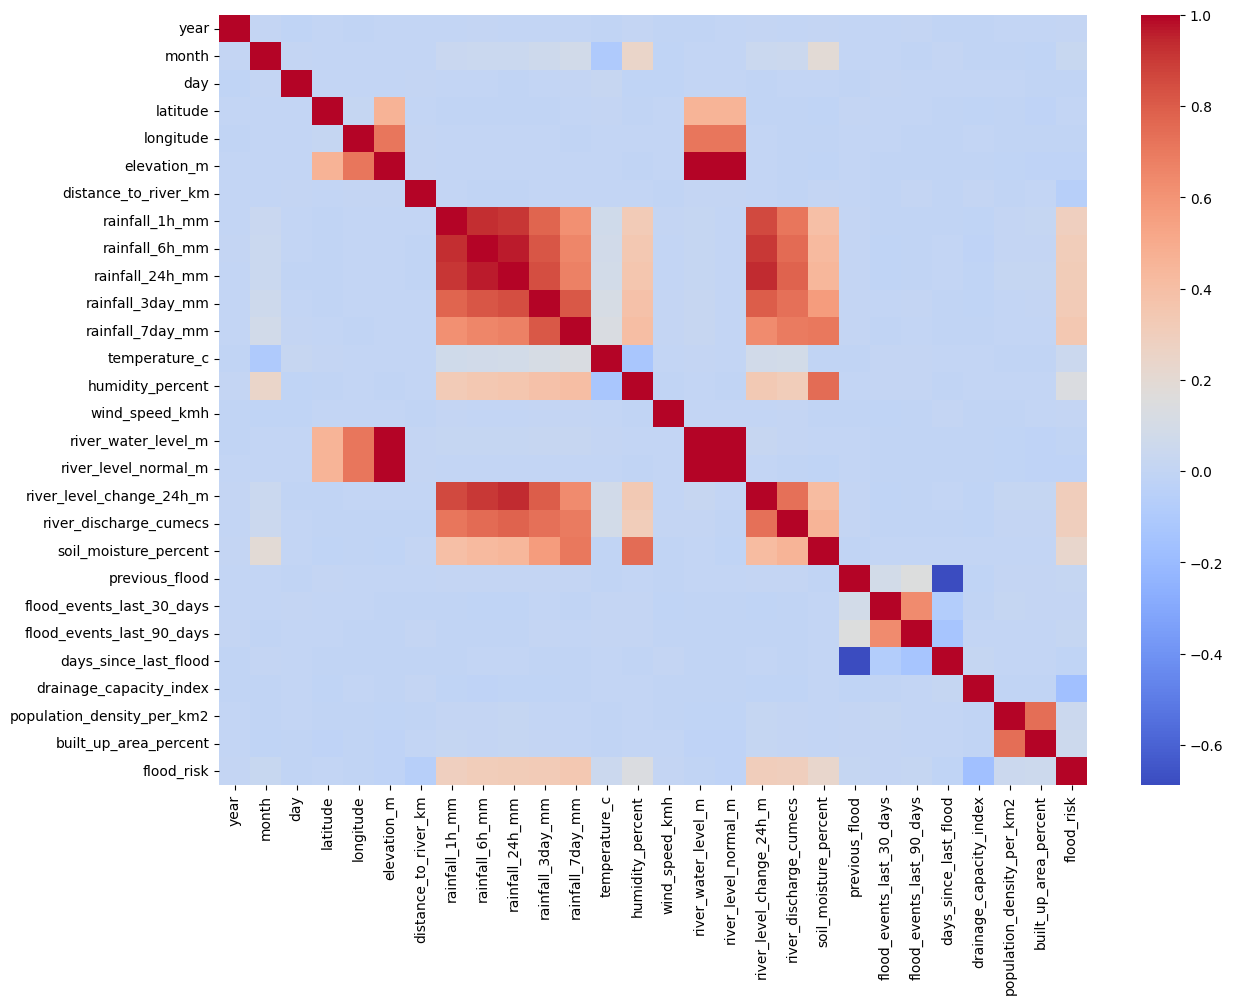

In [16]:
corr=df.select_dtypes(include='number').corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr,annot=False,cmap='coolwarm')
plt.show()

In [17]:
df.head()

,date,year,month,day,season,district,tehsil,latitude,longitude,elevation_m,...,flood_events_last_90_days,days_since_last_flood,land_use_type,drainage_condition,embankment_condition,urbanization_level,drainage_capacity_index,population_density_per_km2,built_up_area_percent,flood_risk
0,2019-03-05,2019,3,5,Summer,Fazilka,Fazilka North,30.4053,73.8989,171.8,...,0,5453,Urban,Good,Poor,High,98.1,1317,98.9,1
1,2016-12-08,2016,12,8,Winter,Bathinda,Bathinda Central,30.1747,74.9283,222.9,...,0,6772,Wetland,Moderate,Poor,Low,55.1,237,8.0,0
2,2024-11-29,2024,11,29,Post-Monsoon,Mansa,Mansa Central,29.9604,75.4609,212.9,...,0,9615,Urban,Good,Poor,High,83.0,1952,51.8,0
3,2024-02-21,2024,2,21,Winter,Barnala,Barnala South,30.4950,75.4021,229.2,...,0,5104,Wetland,Good,Good,Low,92.0,357,12.4,0
4,2015-06-28,2015,6,28,Monsoon,Rupnagar,Rupnagar Central,30.9590,76.5200,267.5,...,0,8686,Urban,Good,Moderate,Medium,72.7,629,22.8,0


In [18]:
df.columns

Index(['date', 'year', 'month', 'day', 'season', 'district', 'tehsil',
       'latitude', 'longitude', 'elevation_m', 'distance_to_river_km',
       'rainfall_1h_mm', 'rainfall_6h_mm', 'rainfall_24h_mm',
       'rainfall_3day_mm', 'rainfall_7day_mm', 'temperature_c',
       'humidity_percent', 'wind_speed_kmh', 'river_water_level_m',
       'river_level_normal_m', 'river_level_change_24h_m',
       'river_discharge_cumecs', 'soil_moisture_percent', 'previous_flood',
       'flood_events_last_30_days', 'flood_events_last_90_days',
       'days_since_last_flood', 'land_use_type', 'drainage_condition',
       'embankment_condition', 'urbanization_level', 'drainage_capacity_index',
       'population_density_per_km2', 'built_up_area_percent', 'flood_risk'],
      dtype='str')

In [23]:
df["flood_risk"].unique()

array([1, 0])

In [24]:
df["flood_risk"].value_counts()

flood_risk
0    20000
1     5000
Name: count, dtype: int64